# Customer Churn & Retention Analysis

**Tools:** Python, pandas, NumPy, Matplotlib and Seaborn

## 1. Introduction

Customer churn occurs when customers stop using a company's
services. Understanding churn patterns can help a telecom
provider identify areas where the customer experience
needs improvement.

In this project, I analyze customer profiles, subscriptions,
contracts and billing details. The analysis includes data
cleaning, exploratory visualizations and customer group
comparisons, followed by findings and recommendations.

## 2. Business Use Case

A telecom provider wants to identify customer groups with
higher churn and decide where to focus retention efforts.

This analysis supports that decision by comparing churn
rates, customer volumes and the monthly charges associated
with customers who left. It highlights areas for further
investigation rather than assuming why customers leave.

## 3. Objectives

- Review data quality, missing values and duplicate records.
- Calculate the overall customer churn rate.
- Compare churn across contracts, tenure, services and billing choices.
- Examine tenure and monthly charges alongside churn.
- Identify customer segments that deserve further investigation.
- Recommend practical actions supported by the findings.

## 4. Dataset Information

The dataset contains **7,043 customer records and 21 original
columns**. Each row represents one customer.

| Category | Columns | Description |
|---|---|---|
| Customer identifier | customerID | Unique customer ID |
| Customer profile | gender, SeniorCitizen, Partner, Dependents | Customer and household details |
| Tenure | tenure | Number of months with the company |
| Phone services | PhoneService, MultipleLines | Phone subscription and multiple-line status |
| Internet service | InternetService | DSL, fiber optic or no internet |
| Additional services | OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | Add-on subscription details |
| Account details | Contract, PaperlessBilling, PaymentMethod | Contract and billing arrangements |
| Charges | MonthlyCharges, TotalCharges | Monthly and accumulated charges |
| Churn status | Churn | Whether the customer left |

### Important Definitions

- **Churn = Yes:** The customer left the company.
- **Churn = No:** The customer stayed.
- **SeniorCitizen:** A status indicator, not the customer's exact age.
- **Churn rate:** Customers who left divided by all customers
  in the same group, multiplied by 100.
- **No internet service / No phone service:** Separate service
  categories, preserved during analysis.

The currency and collection period are not specified in
the supplied CSV. Combined monthly charges are used for
comparison and should not be interpreted as verified
revenue loss.

## Import Libraries

In [140]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set the chart style
sns.set_theme(style="whitegrid")

# Set colors for customers who stayed and left
COLORS = {"No": "steelblue", "Yes": "coral"}

# Show all columns in DataFrames
pd.set_option("display.max_columns", None)

In [141]:
# because the dataset-loading cell uses Path
from pathlib import Path  

In [142]:
# display() to show tables,
from IPython.display import display  

## Load the Dataset
The original data is kept in `raw`. Cleaning and new analysis columns are applied to a separate copy.

In [4]:
data = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Understand the Data

In [5]:
data.shape

(7043, 21)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
data.describe(include="object")

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [9]:
# Count missing values in each column
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
data.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [11]:
# View the different contract types
data["Contract"].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

### Observation:
The dataset contains 7,043 customers and 21 columns.
It includes customer details, subscribed services, billing
information and churn status.

TotalCharges is stored as text, although it represents
a numerical amount. I will check and convert it during
data cleaning.

## Data Cleaning

In [12]:
# Check duplicate rows
data.duplicated().sum()

np.int64(0)

In [13]:
# Check duplicate customer IDs
data["customerID"].duplicated().sum()

np.int64(0)

Both results are 0, so no duplicates need to be removed.

In [14]:
# Convert TotalCharges to numbers
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

In [15]:
data.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

11 missing values in TotalCharges

In [16]:
missing_charges = data[data["TotalCharges"].isnull()]
missing_charges[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


These customers have 0 months of tenure. Keeping their records and leave the unknown totals as missing.

In [17]:
# making senior citizen labels easier to read
data["SeniorCitizen"] = data["SeniorCitizen"].replace({
    0: "No",
    1: "Yes"
})

In [18]:
# Creating a numerical churn column
data["ChurnFlag"] = data["Churn"].map({
    "No": 0,
    "Yes": 1
})

The original Churn column stays unchanged. The new column makes calculating churn rates easier.

In [19]:
# Grouping customers by tenure
data["TenureGroup"] = pd.cut(data["tenure"], bins=[-1, 12, 24, 36, 48, 72], labels=["0–12", "13–24", "25–36", "37–48", "49–72"])

For example, a customer with 8 months of tenure belongs to 0–12, while one with 20 months belongs to 13–24.

In [20]:
data[["TotalCharges", "SeniorCitizen", "Churn", "ChurnFlag", "TenureGroup"]].head()

,TotalCharges,SeniorCitizen,Churn,ChurnFlag,TenureGroup
0,29.85,No,No,0,0–12
1,1889.50,No,No,0,25–36
2,108.15,No,Yes,1,0–12
3,1840.75,No,No,0,37–48
4,151.65,No,Yes,1,0–12


### Data Cleaning Summary

- No duplicate rows or customer IDs were found.
- Converted TotalCharges from text to a numerical column.
- Found 11 missing TotalCharges values, all for customers with zero tenure.
- Kept these records and left their unknown charges as missing.
- Changed SeniorCitizen values from 0/1 to No/Yes for readability.
- Created ChurnFlag for calculating churn rates.
- Created tenure groups to compare customers by their time with the company.
- Kept "No internet service" and "No phone service" as separate categories.

### Overall Churn rate

In [21]:
# Calculating the percentage of customers who left
churn_rate = data["ChurnFlag"].mean() * 100
print("Overall churn rate:", round(churn_rate, 2), "%")

Overall churn rate: 26.54 %


Because ChurnFlag contains 1 for customers who left and 0 for customers who stayed, its mean gives the proportion who left.

About 27 out of every 100 customers in this dataset left
the company. I will use this overall churn rate to compare
different customer groups.

## Exploratory Data Analysis (EDA)

In this section, I explore customer details, services,
contracts and charges to identify patterns related to churn.

### How many customers stayed and left?

In [22]:
#  Count customers who stayed and left
churn_counts = data["Churn"].value_counts()
churn_counts

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [23]:
churn_percentage = data["Churn"].value_counts(normalize=True) * 100
churn_percentage.round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

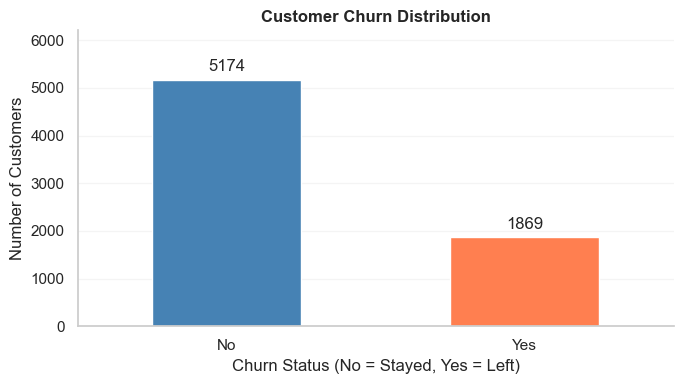

In [138]:
ax = churn_counts.reindex(["No", "Yes"]).plot(kind="bar", figsize=(7, 4), color=["steelblue", "coral"], rot=0, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn Distribution", fontweight="bold")
plt.xlabel("Churn Status (No = Stayed, Yes = Left)")
plt.ylabel("Number of Customers")
plt.ylim(0, churn_counts.max() * 1.2)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

- 5,174 customers (73.46%) stayed with the company.
- 1,869 customers (26.54%) left the company.
- Around 27 out of every 100 customers in this dataset churned.

Next, I will compare customer groups to identify where
churn is higher and where retention efforts could be focused.

### Customer Tenure and Churn

Tenure is the number of months a customer has stayed
with the company. Here, I compare tenure for customers
who stayed and those who left.

### compare the tenure distributions

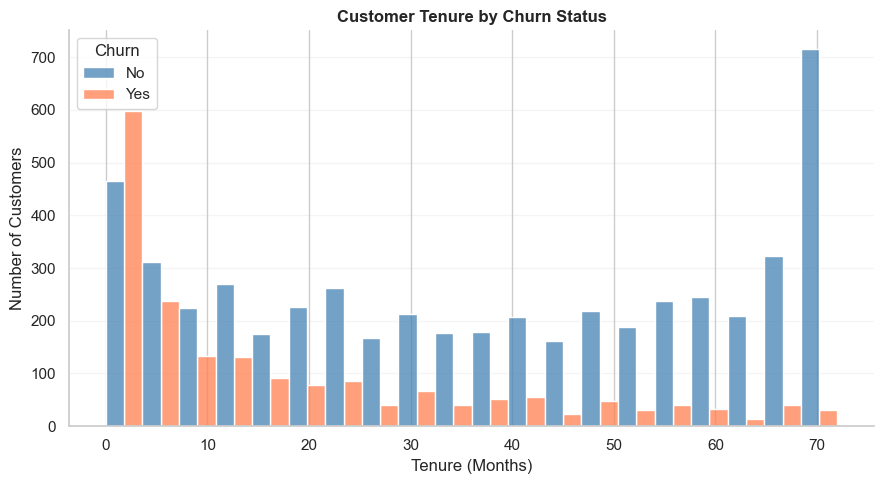

In [137]:
plt.figure(figsize=(9, 5))
sns.histplot(data=data, x="tenure", hue="Churn", hue_order=["No", "Yes"], palette={"No": "steelblue", "Yes": "coral"}, bins=20, multiple="dodge", edgecolor="white")

plt.title("Customer Tenure by Churn Status", fontweight="bold")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

hue="Churn" separates customers by churn status. multiple="dodge" places their bars beside each other.

Customers who left are concentrated at shorter tenures.
This suggests that the early customer experience is an
important area to investigate.

The bars show customer counts, not churn percentages
within each tenure range.

### comparing the median and spread

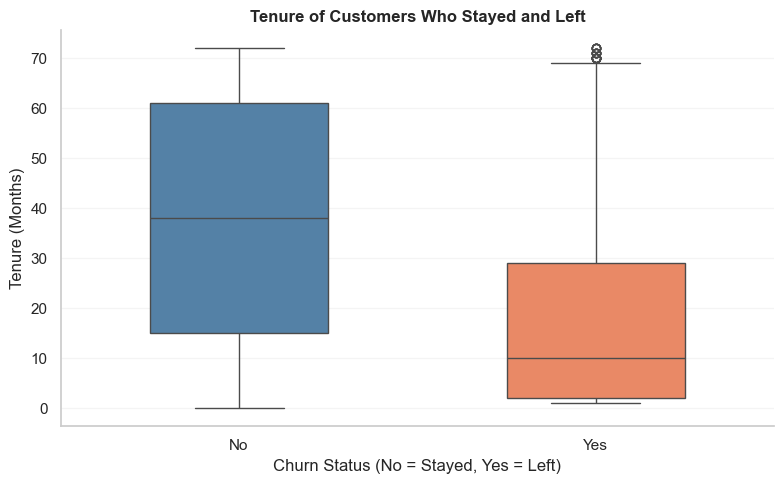

In [136]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="Churn", y="tenure", order=["No", "Yes"], hue="Churn", palette={"No": "steelblue", "Yes": "coral"}, legend=False, width=0.5)

plt.title("Tenure of Customers Who Stayed and Left", fontweight="bold")
plt.xlabel("Churn Status (No = Stayed, Yes = Left)")
plt.ylabel("Tenure (Months)")
plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

The line inside each box is the median tenure.

Customers who left have a median tenure of 10 months,
compared with 38 months for customers who stayed.

The groups overlap, so tenure alone cannot tell us
whether an individual customer will leave. The company
could review onboarding and support for newer customers.

In [27]:
data.groupby("Churn")["tenure"].agg(["mean", "median"]).round(2)

,mean,median
Churn,,
No,37.57,38.0
Yes,17.98,10.0


### Monthly Charges and Churn

I compare monthly charges to understand whether customers
who left had higher bills than customers who stayed.

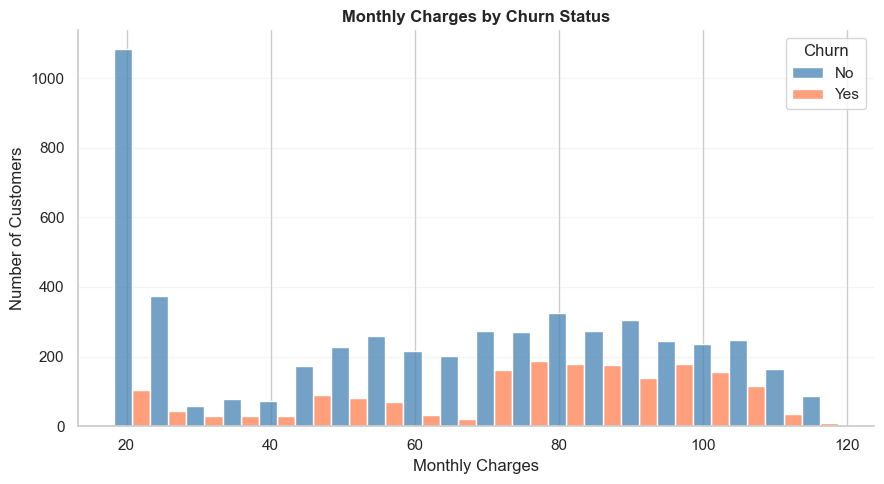

In [135]:
plt.figure(figsize=(9, 5))
sns.histplot(data=data, x="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"], palette={"No": "steelblue", "Yes": "coral"}, bins=20, multiple="dodge", edgecolor="white")

plt.title("Monthly Charges by Churn Status", fontweight="bold")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

Business insight:

Customers who left are more concentrated in the higher
monthly-charge ranges, while many customers who stayed
have low monthly charges.

The chart shows customer counts, not churn rates within
each price range. It does not prove that higher bills
caused customers to leave.

### Box plot

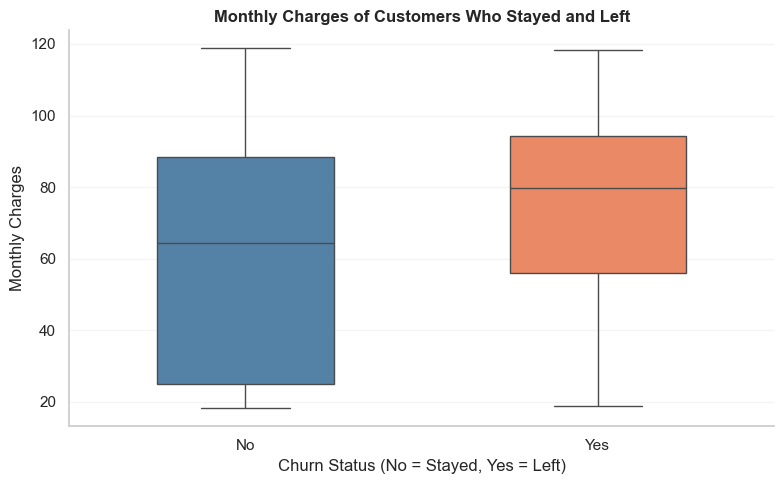

In [134]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="Churn", y="MonthlyCharges", order=["No", "Yes"], hue="Churn", palette={"No": "steelblue", "Yes": "coral"},legend=False, width=0.5)

plt.title("Monthly Charges of Customers Who Stayed and Left", fontweight="bold")
plt.xlabel("Churn Status (No = Stayed, Yes = Left)")
plt.ylabel("Monthly Charges")
plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

Business insight:

The median monthly charge is 79.65 for customers who left,
compared with 64.43 for customers who stayed.

The company could investigate whether customers feel
their plans offer good value. Contract type and subscribed
services should also be considered before suggesting
price changes.

In [30]:
# Comparing the exact values
data.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2)

,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


### Total Charges and Churn

TotalCharges is the total amount charged to a customer
during their time with the company. I compare it across
customers who stayed and those who left.

In [31]:
# Excluding missing totals for this analysis
charges_data = data.dropna(subset=["TotalCharges"])

This excludes the 11 missing totals from charges_data. Main data remains unchanged.

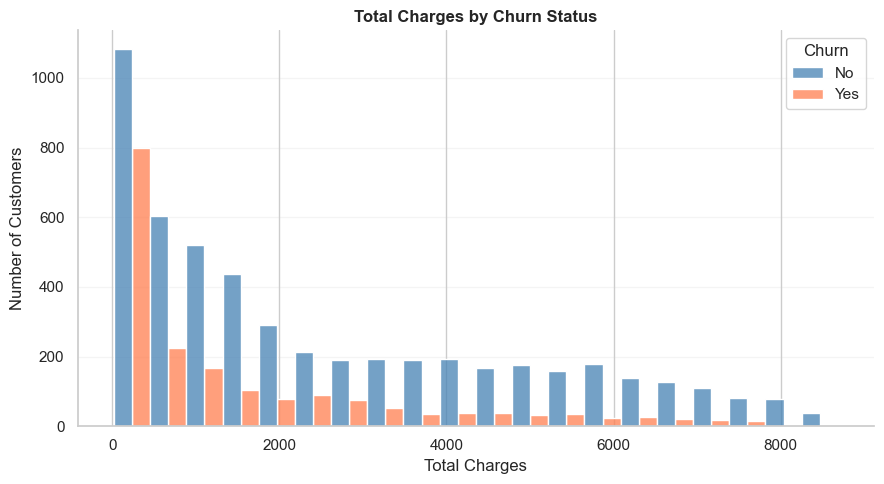

In [133]:
plt.figure(figsize=(9, 5))
sns.histplot(data=charges_data, x="TotalCharges", hue="Churn", hue_order=["No", "Yes"], palette={"No": "steelblue", "Yes": "coral"}, bins=20, multiple="dodge", edgecolor="white")

plt.title("Total Charges by Churn Status", fontweight="bold")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

Business insight:

Customers who left are concentrated toward lower total
charges. This may reflect their shorter time with the
company, giving them less time to accumulate charges.

The bars show customer counts, not churn rates within
each charge range.

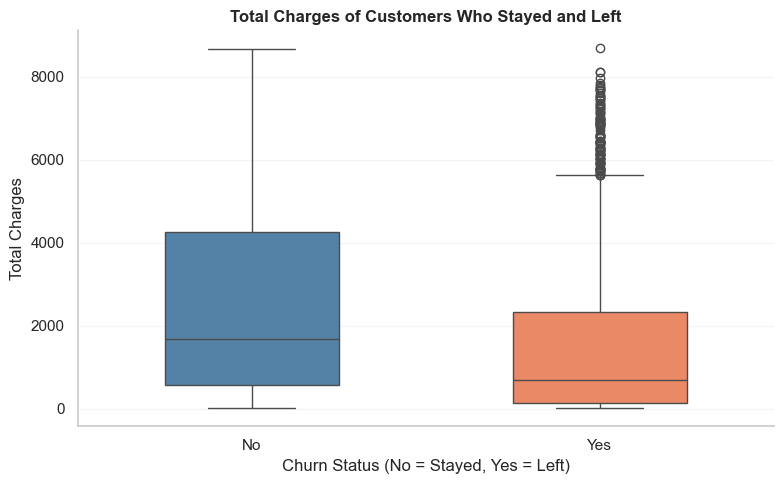

In [132]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=charges_data, x="Churn", y="TotalCharges", order=["No", "Yes"], hue="Churn", palette={"No": "steelblue", "Yes": "coral"}, legend=False, width=0.5)

plt.title("Total Charges of Customers Who Stayed and Left", fontweight="bold")
plt.xlabel("Churn Status (No = Stayed, Yes = Left)")
plt.ylabel("Total Charges")
plt.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

Business insight:

Customers who left have median total charges of 703.55,
compared with 1,683.60 for customers who stayed.

Total charges should be considered alongside tenure
and monthly charges. Lower accumulated charges do not
necessarily mean a customer has less future value.

The dots above the whiskers represent unusually high
values within each group, not necessarily data errors.

In [34]:
charges_data.groupby("Churn")["TotalCharges"].agg(["mean", "median"]).round(2)

,mean,median
Churn,,
No,2555.34,1683.60
Yes,1531.80,703.55


### Churn by Contract Type

I compare churn rates across month-to-month, one-year
and two-year contracts to identify which group has
the highest percentage of customers leaving.

In [35]:
# Count customers who stayed and left
pd.crosstab(data["Contract"], data["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [36]:
# Calculate churn rates
contract_churn = data.groupby("Contract")["ChurnFlag"].mean() * 100
contract_churn.round(2)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64

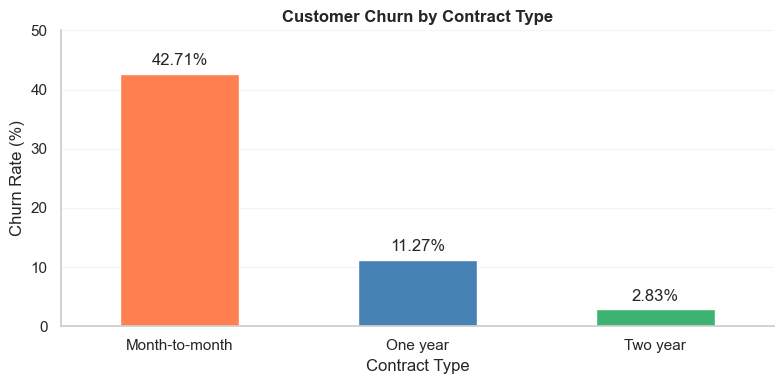

In [131]:
ax = contract_churn.plot(kind="bar", figsize=(8, 4), color=["coral", "steelblue", "mediumseagreen"], rot=0, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Contract Type", fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

- Month-to-month customers have the highest churn rate at 42.71%.
- One-year customers have a churn rate of 11.27%.
- Two-year customers have the lowest churn rate at 2.83%.

Month-to-month customers are a priority for investigating
retention opportunities. The company could review their
experience and test suitable longer-term offers.

However, this comparison does not prove that moving a
customer to a longer contract will prevent churn.

### Churn by Tenure Group

I compare churn rates based on how long customers
have been with the company.

In [38]:
pd.crosstab(data["TenureGroup"], data["Churn"])

Churn,No,Yes
TenureGroup,,
0–12,1149,1037
13–24,730,294
25–36,652,180
37–48,617,145
49–72,2026,213


In [39]:
tenure_churn = data.groupby("TenureGroup", observed=True)["ChurnFlag"].mean() * 100
tenure_churn.round(2)

TenureGroup
0–12     47.44
13–24    28.71
25–36    21.63
37–48    19.03
49–72     9.51
Name: ChurnFlag, dtype: float64

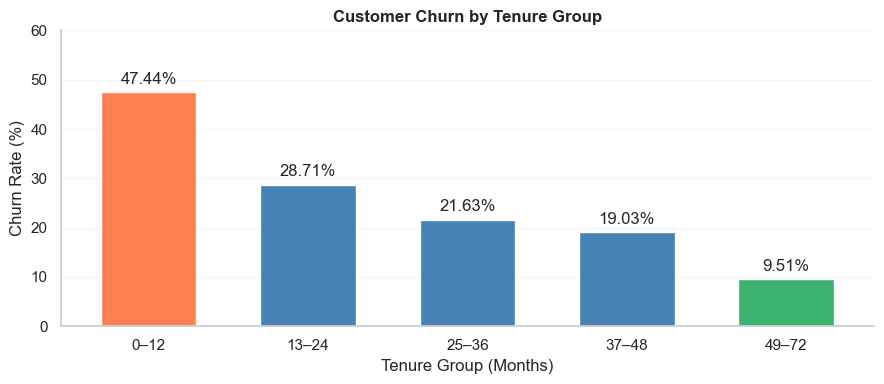

In [130]:
ax = tenure_churn.plot(kind="bar", figsize=(9, 4), color=["coral", "steelblue", "steelblue", "steelblue", "mediumseagreen"], rot=0, width=0.6)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Tenure Group", fontweight="bold")
plt.xlabel("Tenure Group (Months)")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 60)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

- Customers with 0–12 months of tenure have the highest
  churn rate at 47.44%.
- The rate is 28.71% for 13–24 months and falls to 9.51%
  for customers with 49–72 months of tenure.

The company could review onboarding, first-bill clarity
and early support to identify problems newer customers face.

These are comparisons between tenure groups in this
dataset, not changes measured by following the same
customers over time.

### Churn by Internet Service

I compare churn rates for customers using DSL,
fiber optic and no internet service.

In [41]:
pd.crosstab(data["InternetService"], data["Churn"])

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [42]:
internet_churn = data.groupby("InternetService")["ChurnFlag"].mean() * 100
internet_churn.round(2)

InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: ChurnFlag, dtype: float64

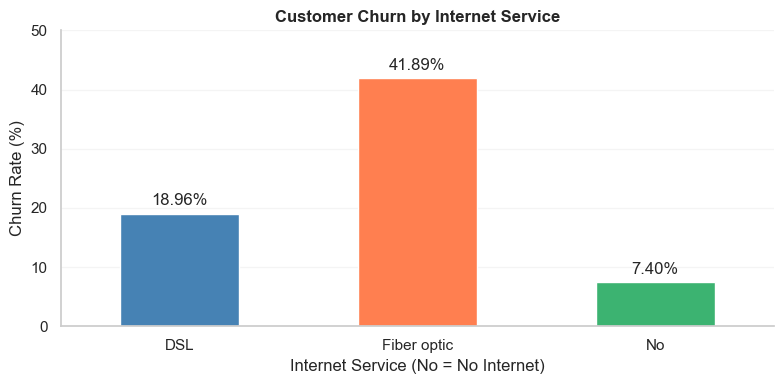

In [129]:
ax = internet_churn.plot(kind="bar", figsize=(8, 4), color=["steelblue", "coral", "mediumseagreen"], rot=0, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Internet Service", fontweight="bold")
plt.xlabel("Internet Service (No = No Internet)")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

- Fiber optic customers have the highest churn rate at 41.89%.
- DSL customers have a churn rate of 18.96%.
- Customers without internet service have a churn rate of 7.40%.

The company could investigate fiber optic pricing,
service quality and customer feedback. This dataset
does not contain complaint or network-quality records,
so the reason for the higher churn remains unclear.

### Churn by Payment Method

I compare churn rates across payment methods to
identify groups that may need further investigation.

In [44]:
pd.crosstab(data["PaymentMethod"], data["Churn"])

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [45]:
payment_churn = data.groupby("PaymentMethod")["ChurnFlag"].mean() * 100
payment_churn.round(2)

PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: ChurnFlag, dtype: float64

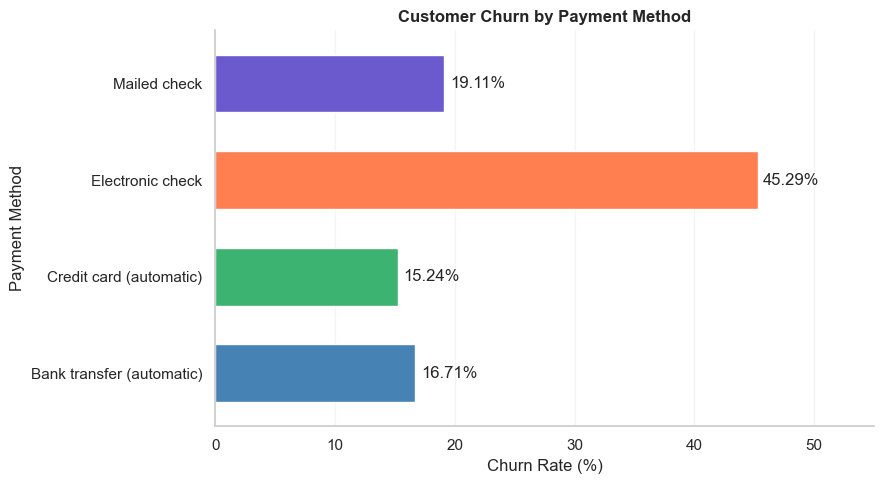

In [128]:
ax = payment_churn.plot(kind="barh", figsize=(9, 5), color=["steelblue", "mediumseagreen", "coral", "slateblue"], width=0.6)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", alpha=0.2)

plt.title("Customer Churn by Payment Method", fontweight="bold")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.xlim(0, 55)
sns.despine()
plt.tight_layout()
plt.show()

kind="barh" creates horizontal bars, making the long payment-method names easier to read.

### Business Insight

- Electronic check customers have the highest churn rate at 45.29%.
- Mailed check customers have a churn rate of 19.11%.
- Automatic bank transfer customers have a rate of 16.71%.
- Automatic credit card customers have the lowest rate at 15.24%.

The company could review billing issues and payment
experiences among electronic check customers. However,
these customers may also differ in tenure and contract
type. Switching payment methods alone is not proven
to reduce churn.

### Churn by Paperless Billing

I compare churn rates for customers who use paperless
billing and those who do not.

In [47]:
pd.crosstab(data["PaperlessBilling"], data["Churn"])

Churn,No,Yes
PaperlessBilling,,
No,2403,469
Yes,2771,1400


In [48]:
billing_churn = data.groupby("PaperlessBilling")["ChurnFlag"].mean() * 100
billing_churn.round(2)

PaperlessBilling
No     16.33
Yes    33.57
Name: ChurnFlag, dtype: float64

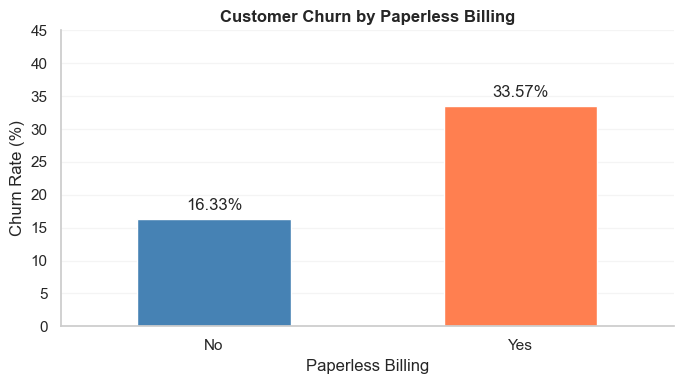

In [127]:
ax = billing_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "coral"], rot=0, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Paperless Billing", fontweight="bold")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 45)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Customers using paperless billing have a churn rate
of 33.57%, compared with 16.33% for those who do not.

The company could review bill clarity and billing-related
feedback. However, this difference does not prove that
paperless billing causes churn. Contract type, charges
and other customer characteristics may also contribute.

### Churn by Gender

I compare churn rates between female and male customers.

In [50]:
pd.crosstab(data["gender"], data["Churn"])

Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


In [51]:
gender_churn = data.groupby("gender")["ChurnFlag"].mean() * 100
gender_churn.round(2)

gender
Female    26.92
Male      26.16
Name: ChurnFlag, dtype: float64

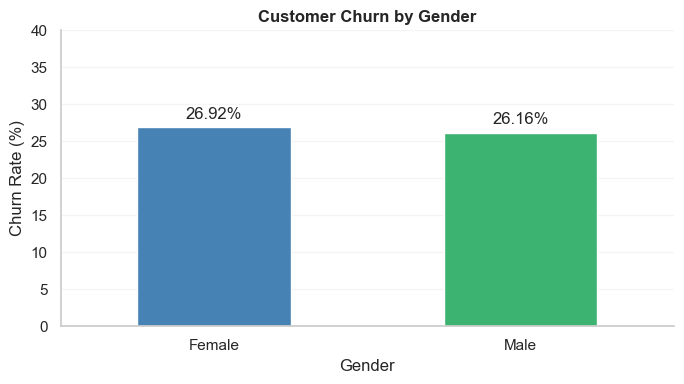

In [126]:
ax = gender_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "mediumseagreen"], rot=0, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Gender", fontweight="bold")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Female customers have a churn rate of 26.92%, while
male customers have a rate of 26.16%.

The rates are very similar. This comparison gives little
reason to prioritize retention efforts based on gender.
Contract type and tenure show larger differences.

### Churn by Senior Citizen Status

I compare churn rates for senior and non-senior customers.

In [53]:
pd.crosstab(data["SeniorCitizen"], data["Churn"])

Churn,No,Yes
SeniorCitizen,,
No,4508,1393
Yes,666,476


In [54]:
senior_churn = data.groupby("SeniorCitizen")["ChurnFlag"].mean() * 100
senior_churn.round(2)

SeniorCitizen
No     23.61
Yes    41.68
Name: ChurnFlag, dtype: float64

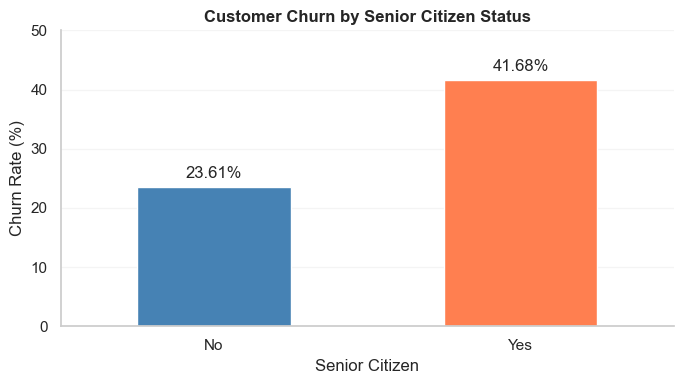

In [125]:
ax = senior_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "coral"], rot=0, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Senior Citizen Status", fontweight="bold")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Senior customers have a churn rate of 41.68%, compared
with 23.61% for non-senior customers.

The company could investigate whether support, billing
explanations and service accessibility meet their needs.
The dataset does not explain the difference, so tenure,
contracts and subscribed services should also be reviewed.

### Churn by Partner Status

I compare churn rates for customers with and without
a partner.

In [56]:
pd.crosstab(data["Partner"], data["Churn"])

Churn,No,Yes
Partner,,
No,2441,1200
Yes,2733,669


In [57]:
partner_churn = data.groupby("Partner")["ChurnFlag"].mean() * 100

partner_churn.round(2)

Partner
No     32.96
Yes    19.66
Name: ChurnFlag, dtype: float64

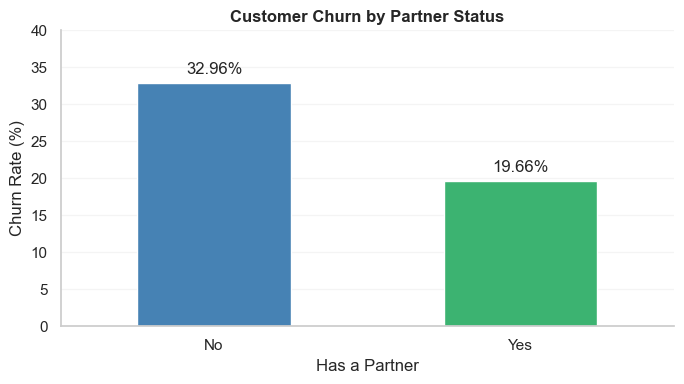

In [124]:
ax = partner_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "mediumseagreen"], rot=0, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Partner Status", fontweight="bold")
plt.xlabel("Has a Partner")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Customers without a partner have a churn rate of 32.96%,
compared with 19.66% for customers with a partner.

This difference may reflect other characteristics,
such as tenure and contract type. Further analysis
should focus on customers' service needs rather than
assuming partner status explains why they leave.

### Churn by Dependents

I compare churn rates for customers with and without
dependents.

In [59]:
pd.crosstab(data["Dependents"], data["Churn"])

Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326


In [60]:
dependents_churn = data.groupby("Dependents")["ChurnFlag"].mean() * 100
dependents_churn.round(2)

Dependents
No     31.28
Yes    15.45
Name: ChurnFlag, dtype: float64

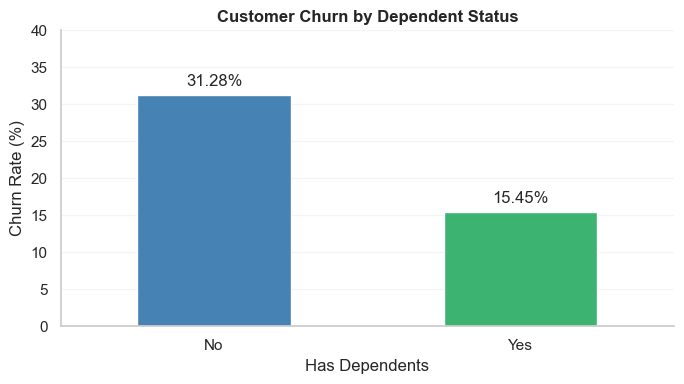

In [123]:
ax = dependents_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "mediumseagreen"], rot=0, width=0.5)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Dependent Status", fontweight="bold")
plt.xlabel("Has Dependents")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Customers without dependents have a churn rate of 31.28%,
compared with 15.45% for customers with dependents.

The difference is worth exploring alongside tenure and
contract type. Having dependents does not itself explain
why a customer stays or leaves. Retention efforts should
focus on customers' needs and service experience.

### Churn by Phone Service

I compare churn rates for customers with and without
a phone service subscription.

In [62]:
pd.crosstab(data["PhoneService"], data["Churn"])

Churn,No,Yes
PhoneService,,
No,512,170
Yes,4662,1699


In [63]:
phone_churn = data.groupby("PhoneService")["ChurnFlag"].mean() * 100
phone_churn.round(2)

PhoneService
No     24.93
Yes    26.71
Name: ChurnFlag, dtype: float64

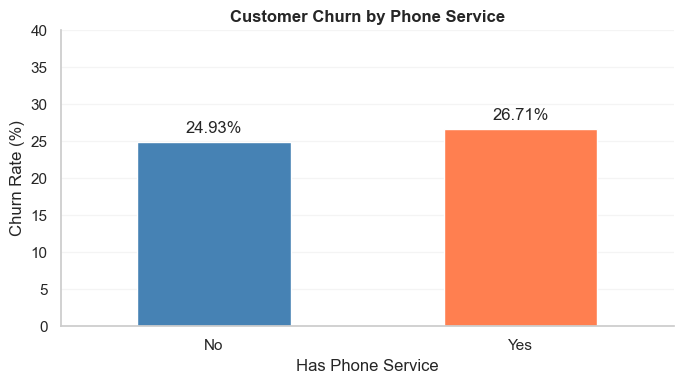

In [121]:
ax = phone_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "coral"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Phone Service", fontweight="bold")
plt.xlabel("Has Phone Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Customers with phone service have a churn rate of 26.71%,
compared with 24.93% for those without it.

The rates are relatively close. Phone subscription alone
offers less separation between churn rates than contract
type or tenure, so it is a lower priority for further
retention analysis.

### Churn by Multiple Lines

I compare customers with multiple phone lines, a single
phone line and no phone service.

"No" means the customer has phone service but does not
have multiple lines. "No phone service" is a separate group.

pd.crosstab(data["MultipleLines"], data["Churn"])

In [65]:
lines_churn = data.groupby("MultipleLines")["ChurnFlag"].mean() * 100
lines_churn.round(2)

MultipleLines
No                  25.04
No phone service    24.93
Yes                 28.61
Name: ChurnFlag, dtype: float64

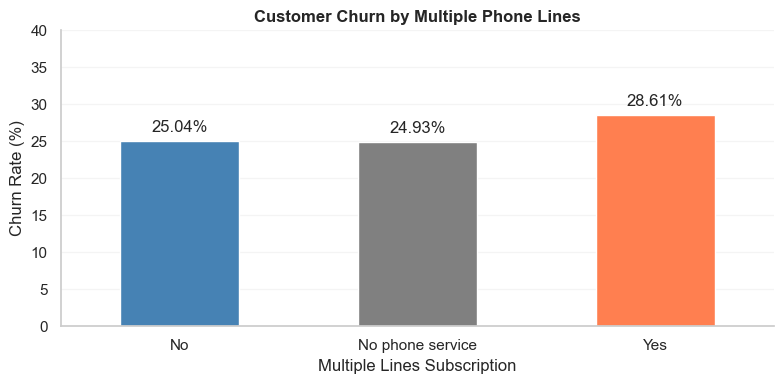

In [120]:
ax = lines_churn.plot(kind="bar", figsize=(8, 4),color=["steelblue", "gray", "coral"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Customer Churn by Multiple Phone Lines", fontweight="bold")
plt.xlabel("Multiple Lines Subscription")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 40)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

- Customers with multiple lines have a churn rate of 28.61%.
- Customers with a single line have a rate of 25.04%.
- Customers without phone service have a rate of 24.93%.

Multiple-line customers have a slightly higher observed
churn rate. The company could review their plans and
service needs, considering monthly charges and contracts.

This comparison does not prove that adding another
phone line increases churn.

### Internet Add-ons and Customer Churn

This section compares churn rates based on subscriptions
to online security, online backup, device protection
and technical support.

Only customers with internet service are included.
This keeps customers without internet separate from
those who have internet but have not subscribed to an add-on.

In [67]:
internet_customers = data[data["InternetService"] != "No"]

!= "No" selects customers whose internet service is DSL or fiber optic

### Online Security and Churn

I compare churn rates between internet customers
with and without online security.

In [68]:
pd.crosstab(internet_customers["OnlineSecurity"], internet_customers["Churn"])

Churn,No,Yes
OnlineSecurity,,
No,2037,1461
Yes,1724,295


In [69]:
security_churn = internet_customers.groupby("OnlineSecurity")["ChurnFlag"].mean() * 100
security_churn.round(2)

OnlineSecurity
No     41.77
Yes    14.61
Name: ChurnFlag, dtype: float64

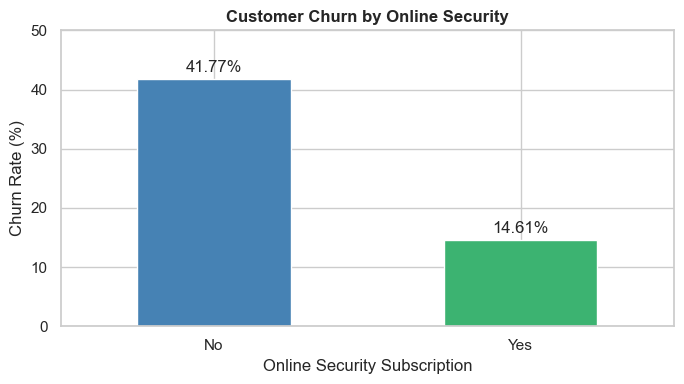

In [72]:
ax = security_churn.plot(kind="bar", figsize=(7, 4),color=["steelblue", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Customer Churn by Online Security", fontweight="bold")
plt.xlabel("Online Security Subscription")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

### Business Insight

Internet customers without online security have a churn
rate of 41.77%, compared with 14.61% for subscribers.

This is a substantial difference. The company could
investigate whether security services meet customer needs
and test relevant offers. However, the comparison does
not prove that subscribing to online security reduces
churn; tenure and contract type may also influence the results.

### Online Backup and Churn

I compare churn rates between internet customers
with and without online backup.

In [73]:
pd.crosstab(internet_customers["OnlineBackup"], internet_customers["Churn"])

Churn,No,Yes
OnlineBackup,,
No,1855,1233
Yes,1906,523


In [74]:
backup_churn = internet_customers.groupby("OnlineBackup")["ChurnFlag"].mean() * 100
backup_churn.round(2)

OnlineBackup
No     39.93
Yes    21.53
Name: ChurnFlag, dtype: float64

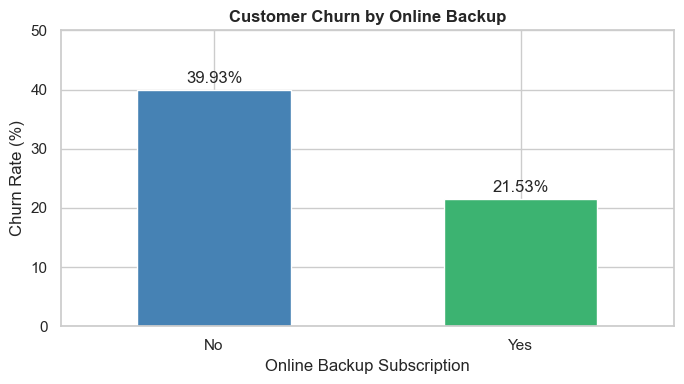

In [75]:
ax = backup_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Customer Churn by Online Backup", fontweight="bold")
plt.xlabel("Online Backup Subscription")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

### Business Insight

Internet customers without online backup have a churn
rate of 39.93%, compared with 21.53% for subscribers.

Backup subscribers show lower observed churn. Reviewing
customer feedback and service usage could help assess
whether backup adds value to their experience. Any
retention offer should be tested before a wider rollout,
as other customer characteristics may explain part
of the difference.

### Device Protection and Churn

I compare churn rates between internet customers
with and without device protection.

In [76]:
pd.crosstab(internet_customers["DeviceProtection"], internet_customers["Churn"])

Churn,No,Yes
DeviceProtection,,
No,1884,1211
Yes,1877,545


In [77]:
protection_churn = internet_customers.groupby("DeviceProtection")["ChurnFlag"].mean() * 100
protection_churn.round(2)

DeviceProtection
No     39.13
Yes    22.50
Name: ChurnFlag, dtype: float64

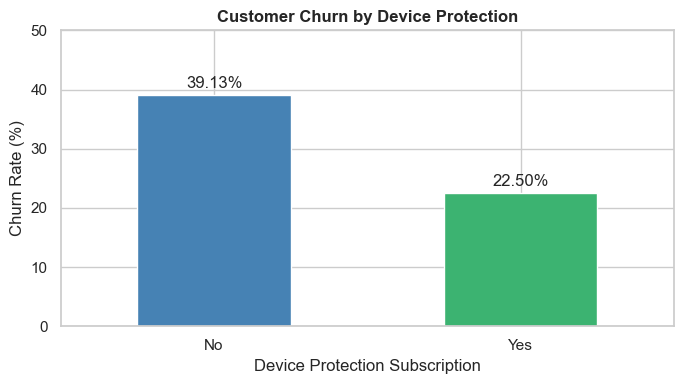

In [78]:
ax = protection_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Customer Churn by Device Protection", fontweight="bold")
plt.xlabel("Device Protection Subscription")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

### Business Insight

Internet customers without device protection have a churn
rate of 39.13%, compared with 22.50% for subscribers.

The company could review how customers use and value
device protection before considering relevant bundles.
The lower churn among subscribers is an association,
rather than evidence that device protection itself
prevents customers from leaving.

### Technical Support and Churn

I compare churn rates between internet customers
with and without a technical support subscription.

In [79]:
pd.crosstab(internet_customers["TechSupport"], internet_customers["Churn"])

Churn,No,Yes
TechSupport,,
No,2027,1446
Yes,1734,310


In [80]:
support_churn = internet_customers.groupby("TechSupport")["ChurnFlag"].mean() * 100
support_churn.round(2)

TechSupport
No     41.64
Yes    15.17
Name: ChurnFlag, dtype: float64

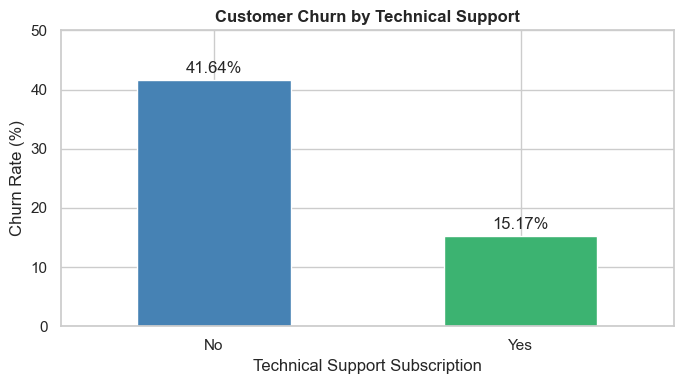

In [81]:
ax = support_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

plt.title("Customer Churn by Technical Support", fontweight="bold")
plt.xlabel("Technical Support Subscription")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

### Business Insight

Internet customers without technical support have a churn
rate of 41.64%, compared with 15.17% for subscribers.

This makes support access and customer experience useful
areas for further investigation. The company could review
support needs and test proactive assistance. The dataset
records subscription status, not support quality or usage,
so it cannot confirm why these churn rates differ.

### Streaming TV and Churn

I compare churn rates for internet customers with
and without a streaming TV subscription.

In [83]:
internet_customers = data[data["InternetService"] != "No"]
tv_churn = internet_customers.groupby("StreamingTV")["ChurnFlag"].mean() * 100
tv_churn.round(2)

StreamingTV
No     33.52
Yes    30.07
Name: ChurnFlag, dtype: float64

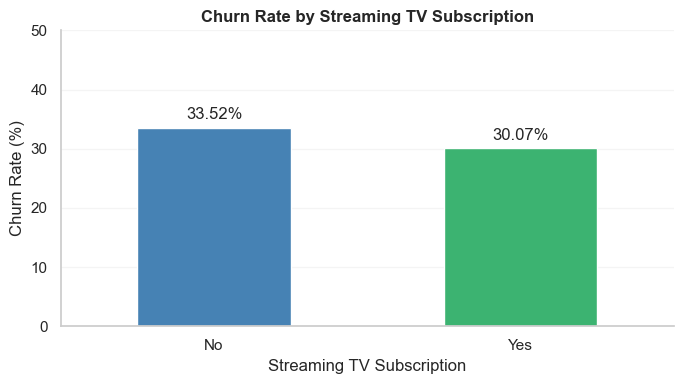

In [85]:
ax = tv_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Churn Rate by Streaming TV Subscription", fontweight="bold")
plt.xlabel("Streaming TV Subscription")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Churn is 33.52% among internet customers without streaming
TV and 30.07% among subscribers.

The difference is relatively small compared with contract
and tenure patterns. Streaming TV subscription alone
provides limited guidance for prioritizing retention efforts.

### Streaming Movies and Churn

I compare churn rates for internet customers with
and without a streaming movies subscription.

In [86]:
movies_churn = internet_customers.groupby("StreamingMovies")["ChurnFlag"].mean() * 100
movies_churn.round(2)

StreamingMovies
No     33.68
Yes    29.94
Name: ChurnFlag, dtype: float64

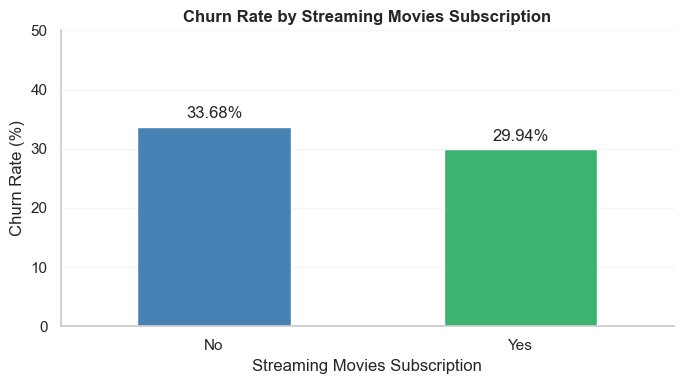

In [87]:
ax = movies_churn.plot(kind="bar", figsize=(7, 4), color=["steelblue", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Churn Rate by Streaming Movies Subscription", fontweight="bold")
plt.xlabel("Streaming Movies Subscription")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Churn is 33.68% among internet customers without streaming
movies and 29.94% among subscribers.

Subscribers have slightly lower observed churn, but this
does not establish that streaming movies improves retention.
Contract type and tenure remain stronger areas to investigate.

### Monthly Charge Bands and Churn

I group monthly charges into four ranges to compare
churn across different billing levels. These ranges
are chosen for reporting, not as proven risk thresholds.

In [89]:
data["ChargeBand"] = pd.cut(data["MonthlyCharges"], bins=[0, 35, 70, 90, float("inf")],labels=["Up to 35", ">35–70", ">70–90", ">90"], include_lowest=True)


float("inf") allows the final group to include any charge above 90.

In [90]:
pd.crosstab(data["ChargeBand"], data["Churn"])

Churn,No,Yes
ChargeBand,,
Up to 35,1546,189
>35–70,1312,413
>70–90,1147,697
>90,1169,570


In [91]:
charge_churn = data.groupby("ChargeBand", observed=True)["ChurnFlag"].mean() * 100
charge_churn.round(2)

ChargeBand
Up to 35    10.89
>35–70      23.94
>70–90      37.80
>90         32.78
Name: ChurnFlag, dtype: float64

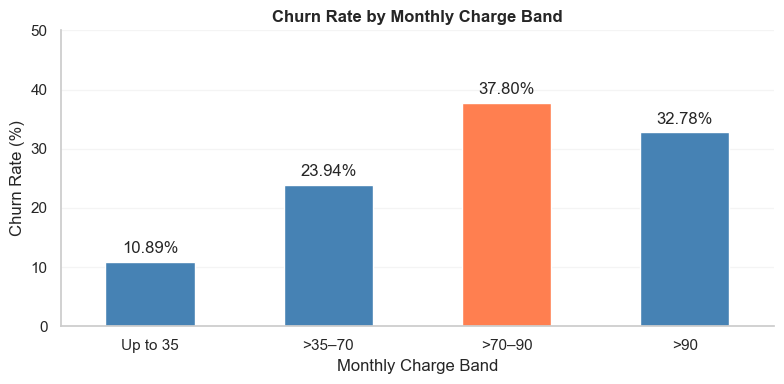

In [92]:
ax = charge_churn.plot(kind="bar", figsize=(8, 4), color=["steelblue", "steelblue", "coral", "steelblue"], rot=0)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Churn Rate by Monthly Charge Band", fontweight="bold")
plt.xlabel("Monthly Charge Band")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
sns.despine()
plt.tight_layout()
plt.show()

The coral bar highlights the band with the highest churn rate.

### Business Insight

- Up to 35: 10.89% churn.
- Above 35 to 70: 23.94% churn.
- Above 70 to 90: 37.80% churn.
- Above 90: 32.78% churn.

The highest churn occurs in the above-70-to-90 band,
rather than the most expensive band. Churn therefore
does not increase consistently with monthly charges.

The company could review plan value in this group,
considering differences in services, contracts and tenure
before recommending price changes.

### Relationships Between Numerical Variables

A correlation heatmap shows the direction and strength
of linear relationships between numerical variables.

Values range from -1 to +1:
- Positive values: the variables tend to increase together.
- Negative values: one tends to decrease as the other increases.
- Values near zero: little linear relationship.

In [93]:
numeric_data = data[["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]]
correlation = numeric_data.corr()

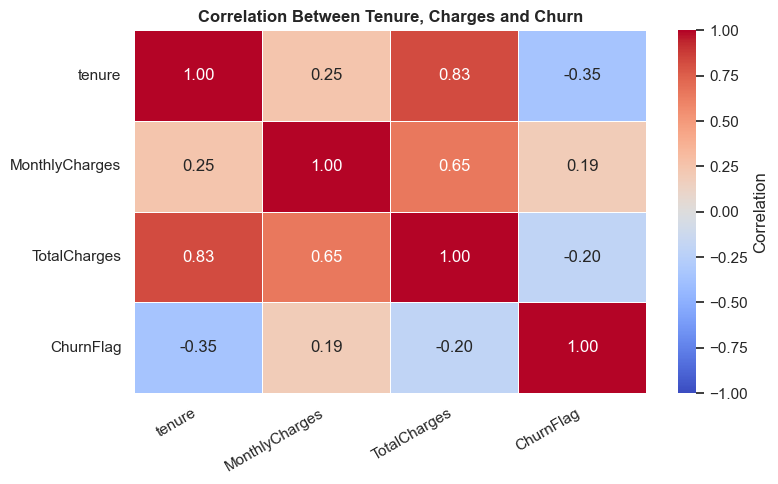

In [94]:
plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Correlation"})

plt.title("Correlation Between Tenure, Charges and Churn", fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Business Insight

- Tenure and churn have a negative correlation of -0.35:
  longer tenure is associated with lower recorded churn.
- Monthly charges and churn have a positive correlation
  of 0.19, indicating a weak positive relationship.
- Tenure and total charges have a strong positive
  correlation of 0.83, consistent with charges accumulating
  over a customer's time with the company.

These relationships support reviewing tenure and charges
together. Correlation does not prove causation. Missing
TotalCharges values are excluded from calculations
involving that column.

### Relationship Between Tenure and Monthly Charges

This chart compares customer tenure and monthly charges,
with colors showing whether the customer stayed or left.

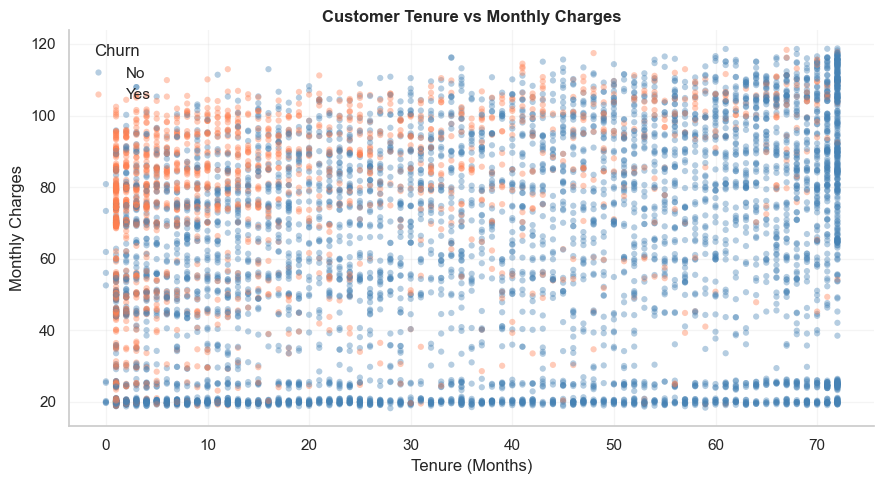

In [95]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=data, x="tenure", y="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"], palette={"No": "steelblue", "Yes": "coral"}, alpha=0.4, s=20, linewidth=0)

plt.title("Customer Tenure vs Monthly Charges", fontweight="bold")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Churn", frameon=False)
plt.grid(alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()


### Business Insight

Customers who left appear across different billing levels,
with a visible concentration at shorter tenure and higher
monthly charges.

This supports reviewing the early experience of customers
on higher-priced plans. However, the groups overlap, and
the chart does not show churn rates within each segment.

### Relationship Between Tenure and Total Charges

This chart explores how accumulated charges vary with
the number of months a customer has stayed.

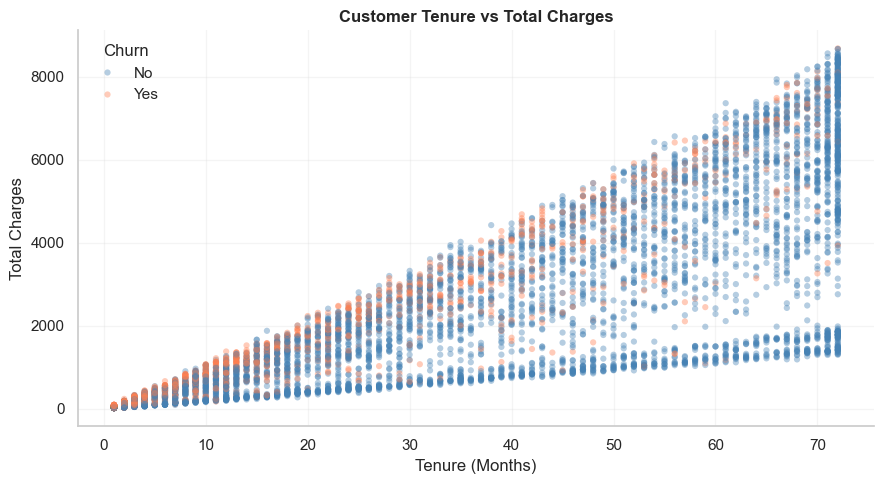

In [96]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=charges_data, x="tenure", y="TotalCharges", hue="Churn", hue_order=["No", "Yes"], palette={"No": "steelblue", "Yes": "coral"}, alpha=0.4, s=20, linewidth=0)

plt.title("Customer Tenure vs Total Charges", fontweight="bold")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges")
plt.legend(title="Churn", frameon=False)
plt.grid(alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()


### Business Insight

Total charges generally increase with tenure because
customers accumulate charges over time.

Customers with similar tenure can have different total
charges because their plans and billing histories differ.
Total charges should therefore be interpreted alongside
tenure and monthly charges, rather than as a separate
measure of customer loyalty.

The 11 missing TotalCharges records are excluded.

## Business Questions and Analysis

This section examines customer characteristics together
to identify more specific patterns in churn.

### Churn by Tenure and Contract Type

I compare tenure groups within each contract type to
identify where churn is concentrated.

In [97]:
pd.crosstab(data["TenureGroup"], data["Contract"])

Contract,Month-to-month,One year,Two year
TenureGroup,,,
0–12,1994,124,68
13–24,737,197,90
25–36,486,250,96
37–48,316,268,178
49–72,342,634,1263


In [98]:
tenure_contract = data.pivot_table( index="TenureGroup", columns="Contract", values="ChurnFlag", aggfunc="mean", observed=True) * 100
tenure_contract.round(2)

Contract,Month-to-month,One year,Two year
TenureGroup,,,
0–12,51.35,10.48,0.00
13–24,37.72,8.12,0.00
25–36,32.51,8.00,2.08
37–48,33.54,13.06,2.25
49–72,26.02,12.93,3.33


pivot_table() arranges tenure groups as rows and contract types as columns. Each value is the churn percentage within that combination.


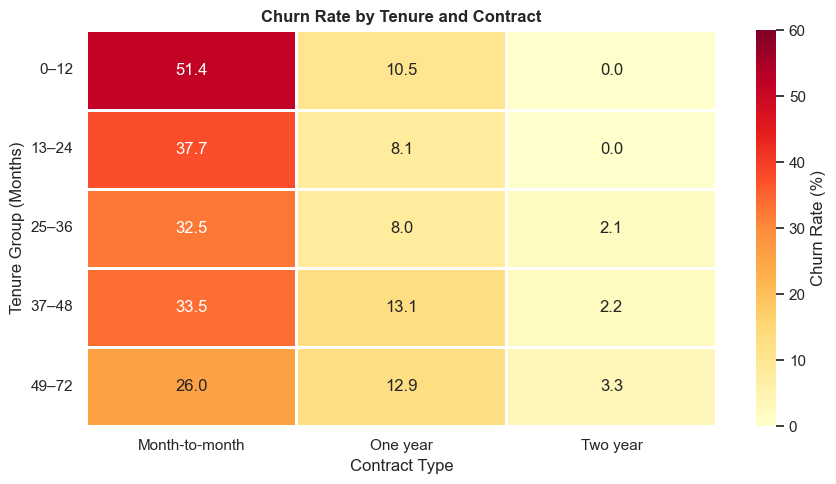

In [99]:
plt.figure(figsize=(9, 5))
sns.heatmap(tenure_contract, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=1, vmin=0, vmax=60, cbar_kws={"label": "Churn Rate (%)"})

plt.title("Churn Rate by Tenure and Contract", fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Tenure Group (Months)")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Business Insight

Month-to-month customers with 0–12 months of tenure
have the highest observed churn rate at 51.4%.
This group contains 1,994 customers.

Month-to-month contracts also have the highest churn
within every other tenure group. The company could
prioritize reviewing onboarding and early support
for these customers.

Some two-year contract groups show 0% churn, but their
sample sizes are small. A zero observed rate does not
guarantee that similar customers will never leave.

### Internet Service and Churn Within Contract Types

I compare internet services within the same contract
type to check whether the fiber optic pattern remains.

In [100]:
pd.crosstab(data["Contract"], data["InternetService"])

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


In [101]:
internet_contract = data.pivot_table(index="Contract", columns="InternetService", values="ChurnFlag", aggfunc="mean") * 100
internet_contract = internet_contract.rename(columns={"No": "No internet"})
internet_contract.round(2)

InternetService,DSL,Fiber optic,No internet
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78


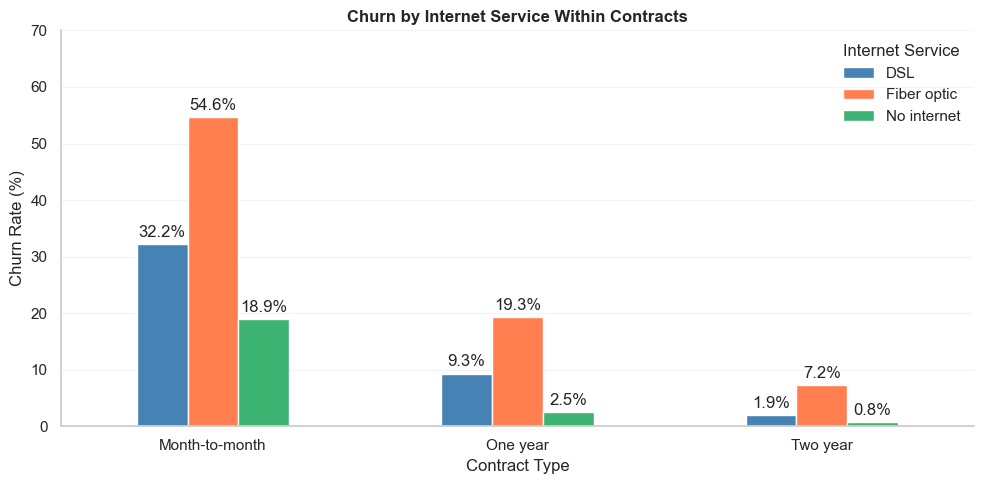

In [102]:
ax = internet_contract.plot(kind="bar", figsize=(10, 5), color=["steelblue", "coral", "mediumseagreen"], rot=0)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.bar_label(ax.containers[1], fmt="%.1f%%", padding=3)
ax.bar_label(ax.containers[2], fmt="%.1f%%", padding=3)

ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)

plt.title("Churn by Internet Service Within Contracts", fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 70)
plt.legend(title="Internet Service", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Fiber optic customers have the highest observed churn
within every contract type:

- Month-to-month: 54.61%.
- One year: 19.29%.
- Two year: 7.23%.

The higher overall churn among fiber optic customers
is therefore not explained entirely by contract type.

The company could investigate fiber pricing, service
quality and customer feedback. Tenure and other account
differences still need to be considered before drawing
conclusions about the cause.

### Churn Volume and Monthly Charges by Contract

I compare the number of customers who left and their
combined monthly charges across contract types.

These charges describe the recorded churned customers.
They are not verified revenue losses for a specific month.

In [103]:
churned_customers = data[data["Churn"] == "Yes"]

In [104]:
contract_counts = churned_customers.groupby("Contract").size()
contract_counts

Contract
Month-to-month    1655
One year           166
Two year            48
dtype: int64

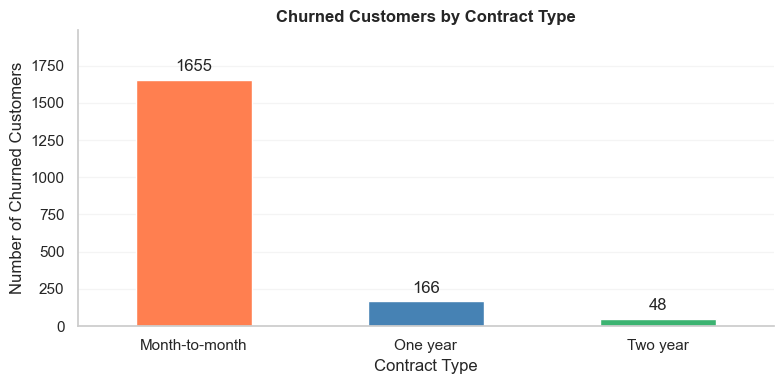

In [105]:
ax = contract_counts.plot(kind="bar", figsize=(8, 4), color=["coral", "steelblue", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)

plt.title("Churned Customers by Contract Type", fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Number of Churned Customers")
plt.ylim(0, contract_counts.max() * 1.2)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Month-to-month contracts account for 1,655 of the 1,869
customers who left, or 88.55% of all observed churn.

This group combines a high churn rate with substantial
customer volume, making it a priority for retention analysis.

In [106]:
# Calculating associated monthly charges
contract_charges = churned_customers.groupby("Contract")["MonthlyCharges"].sum()
contract_charges.round(2)

Contract
Month-to-month    120847.10
One year           14118.45
Two year            4165.30
Name: MonthlyCharges, dtype: float64

In [107]:
# Calculating each contract’s share
contract_charge_share = contract_charges / contract_charges.sum() * 100
contract_charge_share.round(2)

Contract
Month-to-month    86.86
One year          10.15
Two year           2.99
Name: MonthlyCharges, dtype: float64

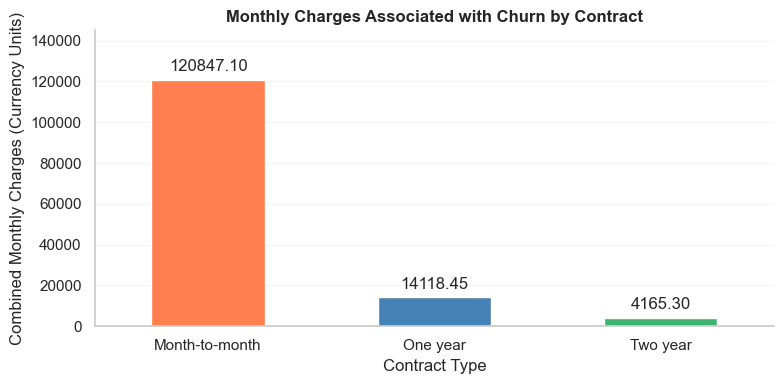

In [108]:
ax = contract_charges.plot(kind="bar", figsize=(8, 4), color=["coral", "steelblue", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)

plt.title("Monthly Charges Associated with Churn by Contract", fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Combined Monthly Charges (Currency Units)")
plt.ylim(0, contract_charges.max() * 1.2)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Month-to-month customers account for 120,847.10 currency
units, representing 86.86% of the churned group's combined
monthly charges.

Across all customers who left, combined monthly charges
total 139,130.85. This supports prioritizing the monthly
contract segment, but the figure should not be presented
as guaranteed recoverable revenue.

In [109]:
# Comparing charges for customers who stayed and left
data.groupby("Churn")["MonthlyCharges"].agg(["count", "mean", "sum"]).round(2)

,count,mean,sum
Churn,,,
No,5174,61.27,316985.75
Yes,1869,74.44,139130.85


### Monthly Charges Associated with Churn by Internet Service

I compare combined monthly charges among customers
who left, grouped by their internet service.

In [110]:
churned_customers["InternetService"].value_counts()

InternetService
Fiber optic    1297
DSL             459
No              113
Name: count, dtype: int64

In [112]:
internet_charges = churned_customers.groupby("InternetService")["MonthlyCharges"].sum()
internet_charges = internet_charges.rename(index={"No": "No internet"})
internet_charges.round(2)

InternetService
DSL             22529.20
Fiber optic    114300.05
No internet      2301.60
Name: MonthlyCharges, dtype: float64

In [113]:
internet_charge_share = internet_charges / internet_charges.sum() * 100
internet_charge_share.round(2)

InternetService
DSL            16.19
Fiber optic    82.15
No internet     1.65
Name: MonthlyCharges, dtype: float64

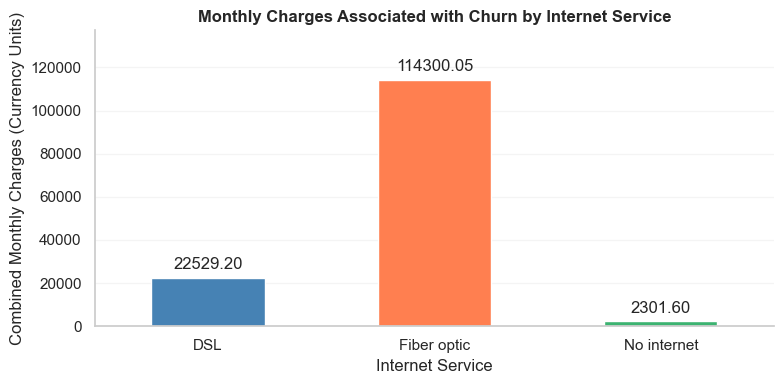

In [114]:
ax = internet_charges.plot(kind="bar", figsize=(8, 4), color=["steelblue", "coral", "mediumseagreen"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)

plt.title("Monthly Charges Associated with Churn by Internet Service", fontweight="bold")
plt.xlabel("Internet Service")
plt.ylabel("Combined Monthly Charges (Currency Units)")
plt.ylim(0, internet_charges.max() * 1.2)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

### Business Insight

Fiber optic customers account for 114,300.05 currency
units, or 82.15% of monthly charges associated with
customers who left.

Its high churn rate and large charge contribution support
a focused review of the fiber customer experience.

The contract and internet-service totals describe the same
customers from different perspectives and must not be
added together.

### A Priority Segment for Retention Investigation

Based on the earlier findings, I examine customers who
meet all three conditions:

- Month-to-month contract.
- Tenure of 12 months or less.
- Fiber optic internet.

This is an exploratory segment, not a validated prediction
of which customers will leave.

In [115]:
priority_mask = ((data["Contract"] == "Month-to-month") & (data["tenure"] <= 12) & (data["InternetService"] == "Fiber optic"))
priority_customers = data[priority_mask]
other_customers = data[~priority_mask]

~priority_mask selects everyone outside this segment.

In [116]:
# Comparing customer counts and outcomes
print("Customers in priority segment:", len(priority_customers))
print("Customers outside segment:", len(other_customers))

priority_customers["Churn"].value_counts()

Customers in priority segment: 916
Customers outside segment: 6127


Churn
Yes    643
No     273
Name: count, dtype: int64

In [117]:
priority_rate = priority_customers["ChurnFlag"].mean() * 100
other_rate = other_customers["ChurnFlag"].mean() * 100

segment_rates = pd.Series({
    "Priority segment": priority_rate,
    "Other customers": other_rate
})

segment_rates.round(2)

Priority segment    70.20
Other customers     20.01
dtype: float64

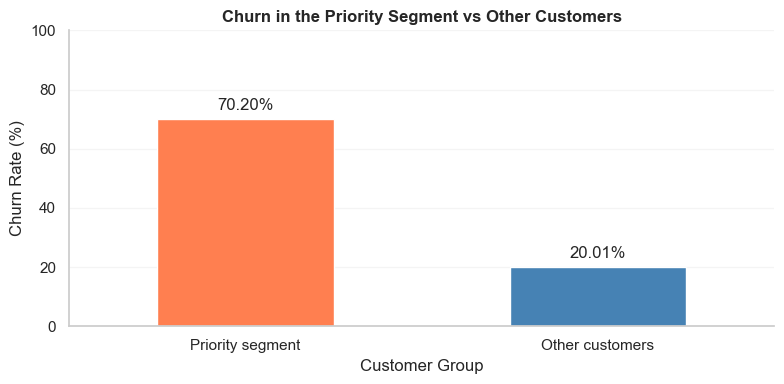

In [118]:
ax = segment_rates.plot(kind="bar", figsize=(8, 4), color=["coral", "steelblue"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)

plt.title("Churn in the Priority Segment vs Other Customers", fontweight="bold")
plt.xlabel("Customer Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", alpha=0.2)
sns.despine()
plt.tight_layout()
plt.show()

In [119]:
churn_share = (priority_customers["ChurnFlag"].sum() / data["ChurnFlag"].sum()) * 100
print("Share of all churn:", round(churn_share, 2), "%")

Share of all churn: 34.4 %


### Business Insight

The priority segment contains 916 customers, of whom
643 left. Its churn rate is 70.20%, compared with 20.01%
among all other customers.

Although it represents a smaller part of the customer
base, it accounts for 34.40% of all observed churn.

There are also 273 customers labelled as non-churned
within this historical segment. The company could use
these characteristics to define a retention trial after
refreshing customer status and eligibility.

The segment was identified using this dataset, so its
performance needs validation on new data.

##  Key Findings

- **Overall churn:** 1,869 out of 7,043 customers left,
  giving a churn rate of 26.54%.

- **Contract type:** Month-to-month customers have the
  highest churn rate at 42.71%, compared with 11.27%
  for one-year and 2.83% for two-year contracts.

- **Customer tenure:** Churn is highest among customers
  with 0–12 months of tenure at 47.44%, compared with
  9.51% among those with 49–72 months.

- **Internet service:** Fiber optic customers have a
  churn rate of 41.89%. Their higher churn remains
  visible within each contract type.

- **Payment method:** Electronic check customers have
  the highest churn rate at 45.29%.

- **Internet add-ons:** Online security and technical
  support subscribers have lower observed churn than
  internet customers without these subscriptions.

- **Monthly charges:** Customers who left paid an average
  of 74.44 per month, compared with 61.27 for customers
  who stayed.

- **Priority segment:** First-year fiber optic customers
  on month-to-month contracts have a churn rate of 70.20%.
  This group accounts for 34.40% of all observed churn.

- **Charge contribution:** Month-to-month customers account
  for 86.86% of the monthly charges associated with
  customers who left.

##  Business Recommendations

### 1. Improve the early customer experience
Review onboarding, installation follow-ups and first-bill
explanations, particularly for newer month-to-month customers.

### 2. Investigate fiber optic customer concerns
Review complaints, network performance and plan pricing
to understand the higher churn among fiber optic customers.

### 3. Test suitable longer-term plans
Offer clear, optional longer-term plans to customers whose
needs fit. Test whether these offers improve retention
before introducing them more widely.

### 4. Review the billing experience
Investigate payment failures and billing confusion among
electronic check customers. Provide clear payment guidance
and convenient payment options.

### 5. Review security and support needs
Explore whether relevant security or support services
would improve the customer experience. Lower churn among
subscribers does not prove that adding these services
will prevent customers from leaving.

### Measuring Success
Start with a small trial and compare results with a similar,
randomly selected group receiving the usual service.
Track churn over a defined period, customer feedback
and the cost of the intervention.

## Limitations

- The dataset does not contain customer acquisition or
  churn dates, so monthly trends and retention over time
  cannot be measured reliably.

- The analysis identifies associations, not the exact
  reasons customers left.

- Customer complaints, network performance, competitor
  offers and satisfaction scores are not available.

- TotalCharges is missing for 11 customers. These records
  are excluded only from analyses involving that column.

- Some customer groups are small, so their churn rates
  should be interpreted carefully.

- The priority segment was selected after exploring this
  dataset and needs validation using new data.

- Combined monthly charges are not verified revenue loss,
  profit or guaranteed savings from a retention campaign.

- The dataset's collection period and currency are not
  documented in the supplied file. Findings may differ
  for other customer populations.

- This project focuses on exploratory analysis and does
  not include a predictive model.

##  Conclusion

This analysis highlights newer customers on month-to-month
contracts, particularly fiber optic subscribers, as a useful
starting point for retention investigations.

Contract type, tenure, internet service and billing choices
show clear differences in observed churn. However, these
patterns do not explain the exact reasons customers leave.

The next step is to combine these findings with customer
feedback and service records, then test focused improvements
to onboarding, billing and support. This would help the
business decide which actions improve retention.

##  Future Scope

- Build a Power BI or Tableau dashboard to explore churn
  rates, customer counts and charge contributions.

- Add customer start and cancellation dates to analyze
  retention patterns over time.

- Include complaints, support tickets and network-quality
  data to investigate possible reasons for churn.

- Develop and evaluate a churn prediction model using
  information available before a customer leaves.

- Test retention campaigns and measure their impact
  on customer retention and profitability.

- Repeat the analysis with updated data to check whether
  the identified patterns remain consistent.